# Supplementary Figure S6e. Hallmark and SCENIC TransMap annotations modelled with TransMap-eGene and TransMap-local

Heritability enrichment and marginal τ* of each annotation in its own model, and joint τ* from one model containing TransMap-eGene-MaxPIP, TransMap-local-MaxPIP (Hotspot WPC), SCENIC-regulon TransMap and MSigDB-Hallmark TransMap annotations (`Joint_TransMap_Functional`). Source: `Functional_Program_comparison/sLDSC_TransMap_Functional.ipynb` cells 20-27 and `Manu_Figures/Figure2_Function_Program.ipynb` cell 22 (input `sLDSC_TransMap_Functional_Methods.rds`; the recomputed values match it to machine precision).

Error bars are estimate ± 1.96 × SE (95% CI), as drawn by the source helpers `plotEnrichForest` / `plotTauForest` (sldsc_utils.R). Significance symbols follow the source `pToSymbol`: **** P < 1e-4, *** P < 1e-3, ** P < 0.01, * P < 0.05, . P < 0.1, shown only when the estimate is > 0 (also for enrichment, whose null is 1). P-values are nominal and two-sided; no multiple-testing correction is applied (the rds also carries `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in the panel, for reference only). Dashed lines: 1 for enrichment, 0 for τ*. All S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs with a re-implementation of the author's meta-analysis code.

Input: `data/Figure_S6e_transmap_functional_joint_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S6e_transmap_functional_joint_sldsc.rds")
d

metric,trait_set,trait,annotation,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),TransMap-eGene,Trans_Single,2.747893578,0.12634006,2.873073e-19,3.447688e-18,57
Enrichment,blood_traits,Blood-related traits (22),TransMap-eGene,Trans_Single,2.199174917,0.20218880,1.436264e-04,2.154397e-04,22
Enrichment,brain_traits,Brain-related traits (18),TransMap-eGene,Trans_Single,3.435609946,0.16862553,4.182436e-11,1.672975e-10,18
Enrichment,all_traits,All traits (57),TransMap-local,Hotspot_wPC,2.880688380,0.13918483,4.253659e-16,2.552195e-15,57
Enrichment,blood_traits,Blood-related traits (22),TransMap-local,Hotspot_wPC,2.620053102,0.26007492,2.896798e-04,3.862398e-04,22
Enrichment,brain_traits,Brain-related traits (18),TransMap-local,Hotspot_wPC,3.003577316,0.26800554,7.999808e-08,1.599962e-07,18
Enrichment,all_traits,All traits (57),SCENIC regulon (TransMap),SCENIC_Regulon_wPC,2.483832838,0.14269457,6.391368e-11,1.917410e-10,57
Enrichment,blood_traits,Blood-related traits (22),SCENIC regulon (TransMap),SCENIC_Regulon_wPC,1.479514705,0.26015992,1.674093e-01,1.674093e-01,22
Enrichment,brain_traits,Brain-related traits (18),SCENIC regulon (TransMap),SCENIC_Regulon_wPC,2.989725546,0.22682753,2.675077e-08,6.420184e-08,18


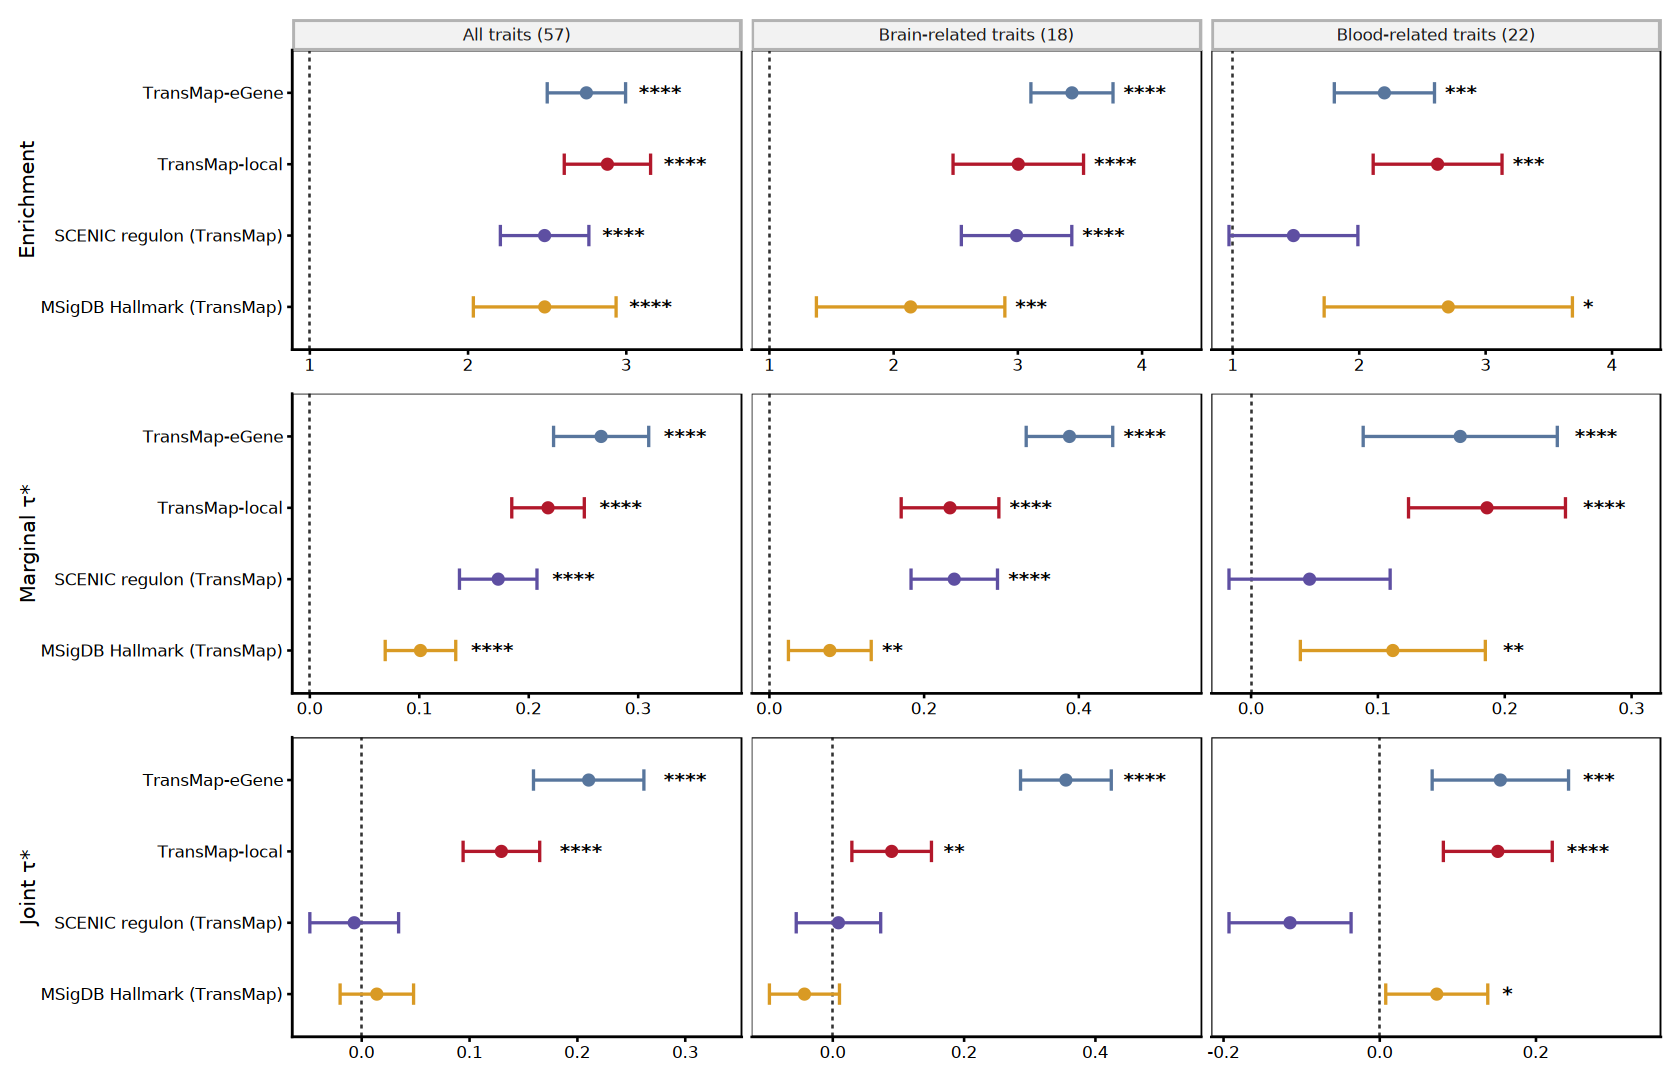

In [2]:
p_sym <- function(p, est) {
  s <- c("****", "***", "**", "*", ".", "")[findInterval(p, c(0, 1e-4, 1e-3, 0.01, 0.05, 0.1, Inf), rightmost.closed = TRUE)]
  ifelse(est > 0, s, "")
}
forest <- function(d, cols, ylab, vline, show_strip = TRUE) {
  d$lo <- d$est - 1.96 * d$se; d$hi <- d$est + 1.96 * d$se
  d$sym <- p_sym(d$pvalue, d$est)
  pad <- 0.03 * diff(range(c(d$lo, d$hi, vline)))
  p <- ggplot(d, aes(y = annotation, colour = annotation)) +
    geom_vline(xintercept = vline, linetype = "dashed", colour = "grey20") +
    geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.3, orientation = "y", linewidth = 0.7) +
    geom_point(aes(x = est), size = 2.6) +
    geom_text(aes(x = hi + pad, label = sym), colour = "black", hjust = 0, size = 4.2, fontface = "bold") +
    facet_grid(. ~ trait, scales = "free_x") +
    scale_colour_manual(values = cols, guide = "none") +
    scale_y_discrete(limits = rev) +
    scale_x_continuous(expand = expansion(mult = c(0.05, 0.22))) +
    labs(x = NULL, y = ylab) +
    theme_classic(base_size = 12) +
    theme(strip.background = element_rect(fill = "grey95", colour = "grey70"),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.4))
  if (!show_strip) p <- p + theme(strip.text = element_blank(), strip.background = element_blank())
  p
}

cols <- c("TransMap-eGene" = "#58769D", "TransMap-local" = "#B2182B",
          "SCENIC regulon (TransMap)" = "#5E4FA2", "MSigDB Hallmark (TransMap)" = "#D99A24")
GROUP <- "annotation"

d$annotation <- d[[GROUP]]
rows <- list(
  forest(subset(d, metric == "Enrichment"), cols, "Enrichment", 1, TRUE),
  forest(subset(d, metric == "Marginal tau*"), cols, expression("Marginal " * tau * "*"), 0, FALSE),
  forest(subset(d, metric == "Joint tau*"), cols, expression("Joint " * tau * "*"), 0, FALSE))
options(repr.plot.width = 14, repr.plot.height = 9)
wrap_plots(rows, ncol = 1)